Expanded MedMCQA analysis checks saved runs and recomputes paired accuracy, round changes, confidence intervals and.


In [1]:
from pathlib import Path
import hashlib, json
from IPython.display import display, Image

def canonical_text(value):
    return str(value).replace(chr(13) + chr(10), chr(10)).replace(chr(13), chr(10))

def canonical_identity(frame):
    return frame.apply(lambda column: column.map(canonical_text))

def locate_repository():
    import os
    start = Path.cwd().resolve()
    for parent in (start, *start.parents):
        if (parent / 'data/limfmed_dataset_gold.csv').is_file() and (parent / 'experiments').is_dir():
            if os.name == 'nt' and (not str(parent).startswith(chr(92) * 2 + '?' + chr(92))):
                return Path(chr(92) * 2 + '?' + chr(92) + str(parent))
            return parent
    raise FileNotFoundError('Run the notebook from inside the repository.')
REPOSITORY_ROOT = locate_repository()
ANALYSIS = REPOSITORY_ROOT / 'experiments/external_benchmarks/medmcqa/benchmark_subsets/expanded_panel_analysis'


In [2]:
from pathlib import Path
import json
import hashlib
import re
from itertools import combinations
import pandas as pd
HERE = ANALYSIS
BASE = HERE.parent
PACKAGE = BASE / 'shared_benchmark_runs'
PRIMARY = PACKAGE / 'runs/primary'
SUBSETS = ['random_dev300', 'shao_hard100', 'goa100', 'marc100', 'marc250']
RUNS = {'Delphi GPT moderator': 'delphi_gpt120_qwen36_deepseekv4', 'Delphi Qwen moderator': 'delphi_qwen36_gpt120_deepseekv4', 'Delphi DeepSeek moderator': 'delphi_deepseekv4_gpt120_qwen36', 'Delphi DeepSeek trio': 'delphi_deepseekv4_trio', 'Delphi Qwen trio': 'delphi_qwen36_trio', 'Delphi GPT trio': 'delphi_gpt120_trio', 'GPT baseline': 'baseline_gpt120', 'Qwen baseline': 'baseline_qwen36', 'DeepSeek baseline': 'baseline_deepseekv4'}
IDENTITY = ['question', 'option_a', 'option_b', 'option_c', 'option_d', 'correct_option_letter']

def digest(p):
    h = hashlib.sha256()
    with p.open('rb') as f:
        for b in iter(lambda: f.read(2 ** 20), b''):
            h.update(b)
    return h.hexdigest()

def option(x):
    s = str(x).strip().upper()[:1]
    return s if s in 'ABCD' else ''

def read(p, homo=False):
    keep = lambda c: c in ['case_id', 'table_source', *IDENTITY, 'winner_selected_option', 'delphi_consensus_selected_option', 'baseline_selected_option', 'delphi_rounds_executed'] or c.endswith(('_tokens', '_cached')) or '_cached__' in c or ('_tokens__' in c) or ('selected_option__' in c) or (homo and c.startswith('r1_raw__'))
    d = pd.read_csv(p, sep=';', dtype=str, usecols=keep, encoding='utf-8-sig').fillna('')
    if 'table_source' in d:
        d = d[d.table_source == 'result_df'].copy()
    return d.set_index('case_id')

def nsum(d, cols):
    return int(sum((pd.to_numeric(d[c], errors='coerce').fillna(0).sum() for c in cols)))

def main():
    rows, configurations, usage_rows, issues, hashes, homo_rows = ([], [], [], [], [], [])
    expected_inputs = {}
    for sub in SUBSETS + ['dev4183']:
        p = PACKAGE / 'data' / (sub + '.csv')
        expected_inputs[sub] = pd.read_csv(p, sep=';', dtype=str, encoding='utf-8-sig').fillna('').set_index('case_id')
    for system, folder in RUNS.items():
        runroot = PRIMARY / folder
        if system == 'DeepSeek baseline':
            runroot = BASE / 'deepseek_baseline_runs/runs/primary' / folder
        for sub in SUBSETS + ['dev4183']:
            csvpath = runroot / (sub + '.csv')
            if not csvpath.exists():
                if sub in SUBSETS:
                    issues.append({'system': system, 'subset': sub, 'issue': 'missing final CSV'})
                continue
            metpath, usepath = (runroot / (sub + '.metrics.json'), runroot / (sub + '.usage.csv'))
            met = json.loads(metpath.read_text(encoding='utf-8-sig'))
            d = read(csvpath, 'trio' in folder)
            expected = expected_inputs[sub]
            ident = len(d) == len(expected) and set(d.index) == set(expected.index) and all((d[c].reindex(expected.index).map(canonical_text).equals(expected[c].map(canonical_text)) for c in IDENTITY))
            if not ident:
                issues.append({'system': system, 'subset': sub, 'issue': 'input identity mismatch'})
            if d.index.duplicated().any():
                issues.append({'system': system, 'subset': sub, 'issue': 'duplicate case ids'})
            ispanel = folder.startswith('delphi_')
            col = 'delphi_consensus_selected_option' if ispanel else 'baseline_selected_option'
            pred = d[col].map(option)
            gold = d.correct_option_letter.map(option)
            ncorrect = int((pred == gold).sum())
            invalid = int((pred == '').sum())
            mismatches = int((pred != d.winner_selected_option.map(option)).sum()) if ispanel else 0
            consensus_only_correct = int(((pred == gold) & (d.winner_selected_option.map(option) != gold)).sum()) if ispanel else 0
            winner_only_correct = int(((pred != gold) & (d.winner_selected_option.map(option) == gold)).sum()) if ispanel else 0
            winner_invalid = int((d.winner_selected_option.map(option) == '').sum()) if ispanel else 0
            calc = met['n'] == len(d) and met['correct'] == ncorrect and (met['invalid_answers'] == invalid) and (abs(met['accuracy'] - ncorrect / len(d)) < 1e-12)
            sha = digest(csvpath)
            output_hash_ok = sha == met['output_sha256']
            input_hash_ok = digest(PACKAGE / 'data' / (sub + '.csv')) == met['input_sha256']
            if not calc or not output_hash_ok or (not input_hash_ok):
                issues.append({'system': system, 'subset': sub, 'issue': 'metric/hash mismatch', 'metric_ok': calc, 'output_hash_ok': output_hash_ok, 'input_hash_ok': input_hash_ok})
            u = pd.read_csv(usepath, sep=';', dtype=str).fillna('')
            prompt = nsum(u, ['prompt_tokens'])
            completion = nsum(u, ['completion_tokens'])
            cost = float(pd.to_numeric(u.cost_rub, errors='coerce').fillna(0).sum())
            limited = int((u.finish_reason == 'length').sum())
            usage_ok = prompt == met['billed_prompt_tokens'] and completion == met['billed_completion_tokens'] and (abs(cost - met['recorded_cost_rub']) < 0.001) and (limited == met['length_limited_calls'])
            if not usage_ok:
                issues.append({'system': system, 'subset': sub, 'issue': 'usage/metric mismatch'})
            config = met['configuration']
            participants = config.get('participants', [])
            configurations.append({'system': system, 'subset': sub, 'configuration_signature': met['configuration_signature'], 'participant_ids': [p['id'] for p in participants], 'participant_models': [p['model_uri'].split('/')[-2] for p in participants], 'organizer': config.get('organizer'), 'temperatures': config.get('temperatures'), 'model_output_limits': config.get('model_output_limits'), 'max_rounds': config.get('max_rounds'), 'early_stop': config.get('early_stop'), 'cache_policy': config.get('cache_policy'), 'reasoning_mode': config.get('reasoning_mode'), 'other_safe_fields': {k: v for k, v in config.items() if k in ['temperature', 'max_tokens', 'output_limit', 'baseline_model', 'source_sha256', 'variant_source_sha256']}})
            cached_cols = [c for c in d if 'cached' in c]
            cached_count = sum((int(d[c].astype(str).str.lower().isin(['true', '1']).sum()) for c in cached_cols))
            prompt_cols = [c for c in d if re.match('(?:r[123]_prompt_tokens__|organizer_after_r[12]_prompt_tokens$|final_synthesis_prompt_tokens$|baseline_prompt_tokens$)', c)]
            completion_cols = [c for c in d if re.match('(?:r[123]_completion_tokens__|organizer_after_r[12]_completion_tokens$|final_synthesis_completion_tokens$|baseline_completion_tokens$)', c)]
            if not ispanel:
                prompt_cols, completion_cols = (['prompt_tokens'], ['completion_tokens'])
            logical_prompt = nsum(d, prompt_cols)
            logical_completion = nsum(d, completion_cols)
            caps = config.get('model_output_limits', {})
            cap = min(caps.values()) if caps else 10000
            capped = pd.DataFrame({c: pd.to_numeric(d[c], errors='coerce').fillna(0).ge(cap) for c in completion_cols})
            capped_cases = int(capped.any(axis=1).sum())
            capped_calls = int(capped.sum().sum())
            rows.append({'system': system, 'subset': sub, 'n': len(d), 'correct': ncorrect, 'accuracy_pct': 100 * ncorrect / len(d), 'invalid': invalid, 'winner_invalid': winner_invalid, 'winner_consensus_mismatch': mismatches, 'consensus_correct_winner_wrong': consensus_only_correct, 'winner_correct_consensus_wrong': winner_only_correct, 'winner_correct': ncorrect - consensus_only_correct + winner_only_correct, 'identical_input': bool(ident), 'metric_ok': bool(calc), 'output_hash_ok': output_hash_ok, 'input_hash_ok': input_hash_ok, 'usage_metrics_ok': bool(usage_ok), 'cached_logical_calls': cached_count, 'billed_calls': len(u), 'billed_prompt_tokens': prompt, 'billed_completion_tokens': completion, 'billed_total_tokens': prompt + completion, 'logical_prompt_tokens': logical_prompt, 'logical_completion_tokens': logical_completion, 'cost_rub': cost, 'cost_per_case_rub': cost / len(d), 'tokens_per_case': (prompt + completion) / len(d), 'length_limited_calls': limited, 'length_limited_pct': 100 * limited / len(u), 'logical_cases_output_at_cap': capped_cases, 'logical_calls_output_at_cap': capped_calls})
            for model, um in u.groupby('model_uri', sort=False):
                usage_rows.append({'system': system, 'subset': sub, 'model': model.split('/')[-2], 'calls': len(um), 'prompt_tokens': nsum(um, ['prompt_tokens']), 'completion_tokens': nsum(um, ['completion_tokens']), 'recorded_cost_rub': float(pd.to_numeric(um.cost_rub).sum()), 'length_limited_calls': int((um.finish_reason == 'length').sum()), 'max_completion_tokens': int(pd.to_numeric(um.completion_tokens).max()), 'mean_completion_tokens': float(pd.to_numeric(um.completion_tokens).mean()), 'finish_reasons': json.dumps(um.finish_reason.value_counts().to_dict()), 'requested_limits': json.dumps(um.max_tokens.value_counts().to_dict())})
            if 'trio' in folder:
                pids = [p['id'] for p in participants]
                opts = [d['r1_selected_option__' + p].map(option) for p in pids]
                r1_all_same = opts[0].eq(opts[1]) & opts[0].eq(opts[2])
                raws = [d['r1_raw__' + p] for p in pids]
                raw_all_same = raws[0].eq(raws[1]) & raws[0].eq(raws[2])
                paircounts = {a + '__' + b: int(d['r1_raw__' + a].eq(d['r1_raw__' + b]).sum()) for a, b in combinations(pids, 2)}
                homo_rows.append({'system': system, 'subset': sub, 'n': len(d), 'cache_policy': config.get('cache_policy'), 'r1_same_option_all_three': int(r1_all_same.sum()), 'r1_same_raw_all_three': int(raw_all_same.sum()), 'r1_same_raw_pairs': paircounts, 'r1_cached_counts': {p: int(d['r1_cached__' + p].str.lower().isin(['true', '1']).sum()) for p in pids}, 'participant_ids': pids, 'all_ids_distinct': len(set(pids)) == len(pids)})
            hashes.append({'system': system, 'subset': sub, 'csv_path': str(csvpath), 'csv_sha256': sha, 'metrics_sha256': digest(metpath), 'usage_sha256': digest(usepath)})
    pd.DataFrame(rows).to_csv(HERE / 'dataset_coverage.csv', index=False, encoding='utf-8-sig')
    pd.DataFrame(usage_rows).to_csv(HERE / 'input_audit_usage_by_model.csv', index=False, encoding='utf-8-sig')
    pivot = pd.DataFrame(rows).pivot(index='system', columns='subset', values='accuracy_pct')
    pivot.to_csv(HERE / 'input_audit_accuracy_pivot.csv', encoding='utf-8-sig')
    result = {'issues': issues, 'configuration': configurations, 'homogeneous_independence_checks': homo_rows, 'input_hashes': hashes, 'outputs': rows, 'note': 'Saved metrics score delphi_consensus_selected_option. winner_selected_option is audited separately. Token/cost totals represent billed usage rows, including retries where recorded, excluding cache hits. DeepSeek trio random_dev300 retains 25 R1 cache hits for each distinct participant (75 total); this is participant-scoped resumption, with no identical raw-answer pairs. Qwen/GPT homogeneous panels retain no R1 cache hits. No DB/notebook execution occurred.'}
    (HERE / 'dataset_coverage.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    print(pivot.round(2).to_string())
    print('Issues:', json.dumps(issues))
    print('Winner mismatches:', json.dumps([{k: r[k] for k in ['system', 'subset', 'winner_consensus_mismatch', 'winner_invalid', 'consensus_correct_winner_wrong', 'winner_correct_consensus_wrong']} for r in rows if r['winner_consensus_mismatch']]))
    print('All new panel configurations use three distinct participant ids, temperatures 0.3, per-call caps 10000, maximum 3 rounds and early stopping.')
    print('Homogeneous R1 identical raw answers:', sum((r['r1_same_raw_all_three'] for r in homo_rows)))
    print('Homogeneous R1 cached calls:', json.dumps([{'system': r['system'], 'subset': r['subset'], 'per_participant': r['r1_cached_counts']} for r in homo_rows if any(r['r1_cached_counts'].values())]))


In [3]:
main()
display(pd.read_csv(ANALYSIS / 'dataset_coverage.csv').head())


subset                     dev4183  goa100  marc100  marc250  random_dev300  shao_hard100
system                                                                                   
DeepSeek baseline            73.66    72.0     75.0     76.4          72.33          24.0
Delphi DeepSeek moderator      NaN    86.0     78.0     83.2          78.33          30.0
Delphi DeepSeek trio           NaN    82.0     75.0     80.4          76.33          35.0
Delphi GPT moderator         77.89    85.0     86.0     83.6          77.00          26.0
Delphi GPT trio                NaN    80.0     76.0     77.2          76.00          29.0
Delphi Qwen moderator          NaN    84.0     81.0     85.2          76.67          26.0
Delphi Qwen trio               NaN    85.0     81.0     83.2          77.00          28.0
GPT baseline                 72.82    77.0     78.0     76.4          75.33          27.0
Qwen baseline                77.48    83.0     82.0     82.0          74.33          31.0
Issues: []

,system,subset,n,correct,accuracy_pct,invalid,winner_invalid,winner_consensus_mismatch,consensus_correct_winner_wrong,winner_correct_consensus_wrong,...,billed_total_tokens,logical_prompt_tokens,logical_completion_tokens,cost_rub,cost_per_case_rub,tokens_per_case,length_limited_calls,length_limited_pct,logical_cases_output_at_cap,logical_calls_output_at_cap
0,Delphi GPT moderator,random_dev300,300,231,77.0,0,0,0,0,0,...,6449932,2811084,3638848,1967.0440,6.556813,21499.773333,0,0.000000,0,0
1,Delphi GPT moderator,shao_hard100,100,26,26.0,0,0,0,0,0,...,2936371,1300098,1636273,891.7371,8.917371,29363.710000,0,0.000000,0,0
2,Delphi GPT moderator,goa100,100,85,85.0,0,0,0,0,0,...,1923546,830760,1092786,587.8225,5.878225,19235.460000,0,0.000000,0,0
3,Delphi GPT moderator,marc100,100,86,86.0,0,0,0,0,0,...,2053434,882550,1170884,626.7965,6.267965,20534.340000,1,0.164204,1,1
4,Delphi GPT moderator,marc250,250,209,83.6,0,0,0,0,0,...,5105514,2196566,2908948,1558.8642,6.235457,20422.056000,0,0.000000,0,0


In [4]:
from __future__ import annotations
import ast
from collections import Counter
import hashlib
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests
HERE = ANALYSIS
SERIES = HERE.parent
ROOT = REPOSITORY_ROOT
PACKAGE = SERIES / 'shared_benchmark_runs'
PRIMARY = PACKAGE / 'runs/primary'
SUBSETS = ['random_dev300', 'shao_hard100', 'goa100', 'marc100', 'marc250']
BASELINES = {'GPT-OSS-120B': PRIMARY / 'baseline_gpt120', 'Qwen3.6-35B-A3B': PRIMARY / 'baseline_qwen36', 'DeepSeek-V4 Flash': SERIES / 'deepseek_baseline_runs/runs/primary/baseline_deepseekv4'}
PANELS = {'delphi_gpt120_qwen36_deepseekv4': {'label': 'GPT organizer (original)', 'organizer_model': 'GPT-OSS-120B', 'homogeneous': False}, 'delphi_qwen36_gpt120_deepseekv4': {'label': 'Qwen organizer', 'organizer_model': 'Qwen3.6-35B-A3B', 'homogeneous': False}, 'delphi_deepseekv4_gpt120_qwen36': {'label': 'DeepSeek organizer', 'organizer_model': 'DeepSeek-V4 Flash', 'homogeneous': False}, 'delphi_deepseekv4_trio': {'label': 'DeepSeek x 3', 'organizer_model': 'DeepSeek-V4 Flash', 'homogeneous': True}, 'delphi_qwen36_trio': {'label': 'Qwen x 3', 'organizer_model': 'Qwen3.6-35B-A3B', 'homogeneous': True}, 'delphi_gpt120_trio': {'label': 'GPT x 3', 'organizer_model': 'GPT-OSS-120B', 'homogeneous': True}}
ORIGINAL = next(iter(PANELS))
IDENTITY = ['question', 'option_a', 'option_b', 'option_c', 'option_d', 'correct_option_letter']
input_provenance = []

def digest(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(2 ** 20), b''):
            h.update(chunk)
    return h.hexdigest()

def read_result(path):
    exact = set(['case_id', 'table_source', *IDENTITY, 'subject_name', 'topic_name', 'baseline_selected_option', 'delphi_consensus_selected_option', 'winner_selected_option', 'delphi_rounds_executed', 'delphi_early_stop_reason'])

    def keep(c):
        return c in exact or (c.startswith(('r1_', 'r2_', 'r3_')) and ('selected_option__' in c or 'confidence__' in c))
    d = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str, usecols=keep).fillna('')
    if 'table_source' in d:
        d = d.loc[d.table_source == 'result_df'].copy()
    else:
        d = d.loc[d.case_id != ''].copy()
    assert not d.case_id.duplicated().any(), f'Duplicate case IDs: {path}'
    assert (d.case_id != '').all(), f'Missing case IDs: {path}'
    input_provenance.append({'path': str(path.relative_to(ROOT)), 'sha256': digest(path), 'n': len(d)})
    d[IDENTITY] = canonical_identity(d[IDENTITY])
    return d.set_index('case_id')

def opt(x):
    s = str(x).strip().upper()[:1]
    return s if s in {'A', 'B', 'C', 'D'} else ''

def plurality(labels, organizer, confidences=None):
    valid_labels = [x for x in labels if x]
    if not valid_labels:
        return ''
    c = Counter(valid_labels)
    tied = [x for x, n in c.items() if n == max(c.values())]
    if len(tied) == 1:
        return tied[0]
    if organizer in tied:
        return organizer
    if confidences is not None:
        scores = {label: 0.0 for label in tied}
        for label, confidence in zip(labels, confidences):
            if label in scores:
                try:
                    scores[label] += float(confidence)
                except (ValueError, TypeError):
                    pass
        return max(tied, key=lambda label: scores[label])
    return tied[0]

def wilson(k, n):
    z = 1.959963984540054
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [centre - half, centre + half]

def paired(a, b):
    a, b = (np.asarray(a, bool), np.asarray(b, bool))
    n10 = int(np.sum(a & ~b))
    n01 = int(np.sum(~a & b))
    return {'n': len(a), 'accuracy_a': float(a.mean()), 'accuracy_b': float(b.mean()), 'difference_pp': float(100 * (a.mean() - b.mean())), 'a_only_correct': n10, 'b_only_correct': n01, 'p_exact': float(binomtest(n10, n10 + n01, 0.5).pvalue) if n10 + n01 else 1.0}

def bootstrap_difference(case_differences, seed=20261011, draws=10000):
    x = np.asarray(case_differences, float)
    if not len(x):
        return [None, None]
    rng = np.random.default_rng(seed)
    means = []
    for start in range(0, draws, 100):
        means.extend(rng.choice(x, size=(min(100, draws - start), len(x)), replace=True).mean(axis=1))
    return [float(v * 100) for v in np.quantile(means, [0.025, 0.975])]

def bootstrap_cluster_ratio(numerators, denominators, seed=20261011, draws=10000):
    numerators, denominators = (np.asarray(numerators), np.asarray(denominators))
    if not denominators.sum():
        return [None, None]
    rng = np.random.default_rng(seed)
    ratios = []
    for start in range(0, draws, 100):
        idx = rng.integers(0, len(numerators), size=(min(100, draws - start), len(numerators)))
        den = denominators[idx].sum(axis=1)
        num = numerators[idx].sum(axis=1)
        ratios.extend(num[den > 0] / den[den > 0])
    return [float(v * 100) for v in np.quantile(ratios, [0.025, 0.975])]

def round_analysis(d, name, group, organizer):
    pids = sorted((c.split('__', 1)[1] for c in d if c.startswith('r1_selected_option__')))
    assert len(pids) == 3, (name, pids)
    truth = d.correct_option_letter.map(opt)
    r1 = d[[f'r1_selected_option__{p}' for p in pids]].map(opt)
    executed = pd.to_numeric(d.delphi_rounds_executed).astype(int)
    last = pd.DataFrame(index=d.index, columns=pids)
    for case in d.index:
        for p in pids:
            last.loc[case, p] = opt(d.loc[case].get(f'r{executed.loc[case]}_selected_option__{p}', ''))
    init_vote = pd.Series([plurality(r1.loc[i].tolist(), opt(d.loc[i, f'r1_selected_option__{organizer}']), [d.loc[i].get(f'r1_confidence__{p}', '') for p in pids]) for i in d.index], index=d.index)
    fin = d.delphi_consensus_selected_option.map(opt)
    contested = executed >= 2
    x = paired(fin[contested].eq(truth[contested]), init_vote[contested].eq(truth[contested]))
    all_x = paired(fin.eq(truth), init_vote.eq(truth))
    r1_correct = r1.eq(truth, axis=0)
    last_correct = last.eq(truth, axis=0)
    r1v, lastv = (r1_correct.to_numpy(), last_correct.to_numpy())
    mask = contested.to_numpy()
    valid_pairs = r1.ne('').to_numpy() & last.ne('').to_numpy()
    individual = paired(lastv[mask][valid_pairs[mask]], r1v[mask][valid_pairs[mask]])
    case_gain_numerators = ((lastv.astype(int) - r1v.astype(int)) * valid_pairs)[mask].sum(axis=1)
    case_gain_denominators = valid_pairs[mask].sum(axis=1)
    for case in d.index:
        j = d.index.get_loc(case)
        round_case_records.append({'group': group, 'panel': name, 'case_id': case, 'contested': bool(contested.loc[case]), 'r1_plurality_correct': bool(init_vote.loc[case] == truth.loc[case]), 'final_correct': bool(fin.loc[case] == truth.loc[case]), 'individual_gain_numerator': int(case_gain_numerators[np.sum(mask[:j])] if mask[j] else 0), 'individual_valid_pairs': int(case_gain_denominators[np.sum(mask[:j])] if mask[j] else 0)})
    row = {'group': group, 'panel': name, 'questions': len(d), 'contested': int(contested.sum()), 'r1_unanimous': int((executed == 1).sum()), 'stopped_after_r2': int((executed == 2).sum()), 'ran_r3': int((executed == 3).sum()), 'mean_rounds': float(executed.mean()), 'accuracy_all_r1_plurality_pct': 100 * all_x['accuracy_b'], 'accuracy_all_final_pct': 100 * all_x['accuracy_a'], 'accuracy_contested_r1_pct': 100 * x['accuracy_b'], 'accuracy_contested_final_pct': 100 * x['accuracy_a'], 'difference_contested_pp': x['difference_pp'], 'repaired': x['a_only_correct'], 'corrupted': x['b_only_correct'], 'p_exact': x['p_exact'], 'changed_option_contested': int(fin[contested].ne(init_vote[contested]).sum()), 'initial_oracle_accuracy_pct': 100 * r1_correct.any(axis=1).mean(), 'final_correct_when_all_r1_wrong': int((fin.eq(truth) & ~r1_correct.any(axis=1)).sum()), 'individual_contested_observations': individual['n'], 'individual_contested_r1_pct': 100 * individual['accuracy_b'], 'individual_contested_last_pct': 100 * individual['accuracy_a'], 'individual_repaired': individual['a_only_correct'], 'individual_corrupted': individual['b_only_correct'], 'individual_difference_pp': individual['difference_pp'], 'individual_case_bootstrap_ci95_pp': bootstrap_cluster_ratio(case_gain_numerators, case_gain_denominators), 'individual_missing_pair_exclusions': int((~valid_pairs[mask]).sum()), 'invalid_round1_decisions': int(r1.eq('').sum().sum()), 'invalid_last_decisions': int(last.eq('').sum().sum()), 'winner_consensus_mismatches': int(d.winner_selected_option.map(opt).ne(fin).sum()) if 'winner_selected_option' in d else None}
    influence = []
    for case in d.index[contested]:
        labels = r1.loc[case].tolist()
        c = Counter(labels)
        if '' in c or len(c) != 2 or max(c.values()) != 2:
            continue
        maj = max(c, key=c.get)
        for p, label in zip(pids, labels):
            influence.append({'case_id': case, 'position': 'majority' if label == maj else 'minority', 'majority_correct': maj == truth.loc[case], 'ended_on_initial_majority': last.loc[case, p] == maj})
    inf = pd.DataFrame(influence)
    inf_summary = []
    if not inf.empty:
        for (position, correct), g in inf.groupby(['position', 'majority_correct']):
            inf_summary.append({'group': group, 'panel': name, 'position': position, 'majority_correct': bool(correct), 'n_decisions': len(g), 'ended_on_initial_majority': int(g.ended_on_initial_majority.sum()), 'share_pct': 100 * g.ended_on_initial_majority.mean()})
    return (row, inf_summary)
METHOD = {name: globals()[name] for name in ['bootstrap_difference', 'digest', 'opt', 'paired', 'plurality', 'read_result', 'wilson']}
opt, paired, bootstrap_difference = (METHOD[name] for name in ('opt', 'paired', 'bootstrap_difference'))

def contrast(a: pd.Series, b: pd.Series, **description) -> dict:
    interval = bootstrap_difference(a.astype(float) - b.astype(float))
    return {**description, **paired(a, b), 'difference_ci_low_pp': interval[0], 'difference_ci_high_pp': interval[1]}

def add_holm(frame: pd.DataFrame, column: str, groups=None) -> pd.DataFrame:
    frame = frame.copy()
    if groups is None:
        frame[column] = multipletests(frame.p_exact, method='holm')[1]
    else:
        frame[column] = frame.groupby(groups, sort=False).p_exact.transform(lambda p: multipletests(p, method='holm')[1])
    return frame

def run_analysis() -> dict:
    input_provenance.clear()
    accuracy, comparisons, versus_original, organizer_pairs, composition_pairs = ([], [], [], [], [])
    independent_controls, full_context = ([], [])
    frames, correct, predictions = ({}, {}, {})
    subset_manifest = json.loads((PACKAGE / 'data_manifest.json').read_text(encoding='utf-8'))
    definitions = {item['id']: item for item in subset_manifest['subsets']}
    for subset in SUBSETS:
        pinned_path = PACKAGE / definitions[subset]['csv']
        assert METHOD['digest'](pinned_path) == definitions[subset]['sha256']
        pinned = pd.read_csv(pinned_path, sep=';', encoding='utf-8-sig', dtype=str, usecols=['case_id', *IDENTITY]).fillna('').set_index('case_id')
        order = pinned.index
        truth = pinned.correct_option_letter.map(opt)
        frames[subset], correct[subset], predictions[subset] = ({}, {}, {})
        all_runs = {**BASELINES, **{name: PRIMARY / name for name in PANELS}}
        for system, directory in all_runs.items():
            path = directory / f'{subset}.csv'
            metadata = json.loads((directory / f'{subset}.metrics.json').read_text(encoding='utf-8'))
            assert METHOD['digest'](path) == metadata['output_sha256']
            assert metadata['input_sha256'] == definitions[subset]['sha256']
            d = METHOD['read_result'](path)
            assert set(d.index) == set(order)
            d = d.reindex(order)
            assert canonical_identity(d[IDENTITY]).equals(canonical_identity(pinned[IDENTITY]))
            prediction_column = 'delphi_consensus_selected_option' if system in PANELS else 'baseline_selected_option'
            p = d[prediction_column].map(opt)
            c = p.eq(truth)
            assert (int(c.sum()), len(c)) == (metadata['correct'], metadata['n'])
            if system in PANELS:
                assert p.equals(d.winner_selected_option.map(opt))
            frames[subset][system], predictions[subset][system], correct[subset][system] = (d, p, c)
            lo, hi = METHOD['wilson'](int(c.sum()), len(c))
            accuracy.append({'subset': subset, 'system_id': system, 'label': PANELS.get(system, {}).get('label', system), 'panel': system in PANELS, 'n': len(c), 'correct': int(c.sum()), 'accuracy_pct': 100 * c.mean(), 'wilson_low_pct': 100 * lo, 'wilson_high_pct': 100 * hi, 'invalid': int(p.eq('').sum())})
        for panel, specification in PANELS.items():
            for baseline in BASELINES:
                own = not specification['homogeneous'] or baseline == specification['organizer_model']
                comparisons.append(contrast(correct[subset][panel], correct[subset][baseline], subset=subset, panel=panel, panel_label=specification['label'], comparator=baseline, own_member=own))
            if panel != ORIGINAL:
                versus_original.append(contrast(correct[subset][panel], correct[subset][ORIGINAL], subset=subset, panel=panel, panel_label=specification['label'], comparator=ORIGINAL))
            if not specification['homogeneous']:
                organizer = specification['organizer_model']
                majority = pd.Series([METHOD['plurality']([predictions[subset][b].loc[i] for b in BASELINES], predictions[subset][organizer].loc[i]) for i in order], index=order).eq(truth)
                oracle = pd.concat([correct[subset][b] for b in BASELINES], axis=1).any(axis=1)
                for name, control in [('independent_baseline_majority_own_organizer_tiebreak', majority), ('independent_baseline_any_correct_oracle', oracle)]:
                    independent_controls.append(contrast(correct[subset][panel], control, subset=subset, panel=panel, panel_label=specification['label'], control=name))
        heterogeneous = [p for p in PANELS if not PANELS[p]['homogeneous']]
        for index, a in enumerate(heterogeneous):
            for b in heterogeneous[index + 1:]:
                organizer_pairs.append(contrast(correct[subset][a], correct[subset][b], subset=subset, panel_a=a, panel_b=b, label_a=PANELS[a]['label'], label_b=PANELS[b]['label']))
        for homogeneous in [p for p in PANELS if PANELS[p]['homogeneous']]:
            heterogeneous_match = next((p for p in heterogeneous if PANELS[p]['organizer_model'] == PANELS[homogeneous]['organizer_model']))
            composition_pairs.append(contrast(correct[subset][homogeneous], correct[subset][heterogeneous_match], subset=subset, homogeneous_panel=homogeneous, heterogeneous_panel=heterogeneous_match, organizer_model=PANELS[homogeneous]['organizer_model']))
    comparisons = add_holm(pd.DataFrame(comparisons), 'p_holm_all_90')
    comparisons = add_holm(comparisons, 'p_holm_15_within_panel', ['panel'])
    comparisons = add_holm(comparisons, 'p_holm_3_within_panel_subset', ['panel', 'subset'])
    own_members = add_holm(comparisons.loc[comparisons.own_member].copy(), 'p_holm_all_60_own_members')
    own_members = add_holm(own_members, 'p_holm_own_members_within_panel', ['panel'])
    comparisons = comparisons.merge(own_members[['panel', 'subset', 'comparator', 'p_holm_all_60_own_members', 'p_holm_own_members_within_panel']], on=['panel', 'subset', 'comparator'], how='left', validate='one_to_one')
    versus_original = add_holm(pd.DataFrame(versus_original), 'p_holm_all_25')
    organizer_pairs = add_holm(pd.DataFrame(organizer_pairs), 'p_holm_all_15')
    composition_pairs = add_holm(pd.DataFrame(composition_pairs), 'p_holm_all_15')
    independent_controls = add_holm(pd.DataFrame(independent_controls), 'p_holm_15_within_control', ['control'])
    independent_controls = add_holm(independent_controls, 'p_holm_5_within_panel_control', ['panel', 'control'])
    accuracy = pd.DataFrame(accuracy)
    summaries = []
    for panel, specification in PANELS.items():
        own = own_members.loc[own_members.panel.eq(panel)]
        panel_comparisons = comparisons.loc[comparisons.panel.eq(panel)]
        wins = []
        for subset in SUBSETS:
            winners = [(name, int(value.sum())) for name, value in correct[subset].items()]
            wins.append({'subset': subset, 'panel': panel, 'highest_observed_accuracy': int(correct[subset][panel].sum()) == max((k for _, k in winners))})
        summaries.append({'panel': panel, 'label': specification['label'], 'homogeneous': specification['homogeneous'], 'subsets_above_all_three_baselines': int(panel_comparisons.groupby('subset').difference_pp.min().gt(0).sum()), 'subsets_above_all_own_members': int(own.groupby('subset').difference_pp.min().gt(0).sum()), 'significant_positive_vs_all_baselines_holm90': int(((panel_comparisons.p_holm_all_90 < 0.05) & (panel_comparisons.difference_pp > 0)).sum()), 'significant_positive_vs_own_members_holm60': int(((own.p_holm_all_60_own_members < 0.05) & (own.difference_pp > 0)).sum()), 'datasets_with_highest_observed_accuracy': int(sum((v['highest_observed_accuracy'] for v in wins)))})
    overlap = []
    for i, a in enumerate(SUBSETS):
        for b in SUBSETS[i + 1:]:
            overlap.append({'subset_a': a, 'subset_b': b, 'shared_ids': len(set(frames[a][ORIGINAL].index) & set(frames[b][ORIGINAL].index))})
    previous = json.loads((SERIES / 'benchmark_condition_comparisons.json').read_text(encoding='utf-8'))
    old_comparisons = pd.DataFrame(previous['paired_comparisons'])
    legacy_accuracy = pd.DataFrame(previous['legacy_train1000_accuracy'])
    historical_rounds = pd.DataFrame(previous['rounds'])
    for system, directory in {**BASELINES, ORIGINAL: PRIMARY / ORIGINAL}.items():
        metadata = json.loads((directory / 'dev4183.metrics.json').read_text(encoding='utf-8'))
        assert METHOD['digest'](directory / 'dev4183.csv') == metadata['output_sha256']
        full_context.append({'system': system, 'label': PANELS.get(system, {}).get('label', system), 'n': metadata['n'], 'correct': metadata['correct'], 'accuracy_pct': 100 * metadata['accuracy'], 'evaluated_for_new_variants': False})
    outputs = {'accuracy': accuracy, 'panel_vs_baselines': comparisons, 'own_member_comparisons': own_members, 'new_vs_original': versus_original, 'organizer_comparisons': organizer_pairs, 'homogeneous_vs_heterogeneous': composition_pairs, 'independent_controls': independent_controls, 'panel_summary': pd.DataFrame(summaries), 'subset_overlap': pd.DataFrame(overlap), 'historical_18_comparisons': old_comparisons, 'historical_train1000_accuracy': legacy_accuracy, 'historical_rounds': historical_rounds, 'full_dev_context': pd.DataFrame(full_context)}
    for name, frame in outputs.items():
        frame.to_csv(HERE / f'comparisons_{name}.csv', index=False, encoding='utf-8-sig')
    methods = {'accuracy': 'Strict recorded single-option accuracy; available reference retained; invalid final predictions are errors.', 'confidence_intervals': '95% Wilson for accuracy; 10,000 paired-question percentile bootstrap samples for differences; seed 20261011; CIs are not simultaneous/multiplicity-adjusted.', 'test': 'Two-sided exact McNemar: binomial test on discordant paired questions, identical previous function.', 'multiplicity': {'panel_vs_baselines': 'All90=6panels x 3baselines x 5sets. Own60=3heterogeneous x3members x5sets +3homogeneous x1member x5sets. Within-panel15 and own-panel families are transparent sensitivity analyses, not interchangeable significance claims.', 'new_vs_original': '25=5newpanels x5sets.', 'organizer': '15=3heterogeneous pairs x5sets; includes fresh-run variation, not an isolated causal organizer effect.', 'composition': '15=3homogeneous-versus-same-organizer-heterogeneous pairs x5sets.', 'independent_controls': "Separate15-test families for independent majority and oracle, heterogeneous panels only. Majority ties follow each panel's organizer."}, 'homogeneous_controls': 'Use saved distinct in-panel first-round calls, analysed in rounds_first_round_controls.csv. Never duplicate a single baseline to invent a three-call oracle.', 'overlap': 'No grand accuracy or independence-based pooled tests across overlapping sets; MARC100 is nested in MARC250.', 'historical_context': 'Preserve original18-test results and train1000 results separately; no new full-dev run exists for five variants.', 'safety': 'Only result CSVs/metrics and previous analysis files read; no experimental notebook/API/SQLite execution.'}
    payload = {'date': '2026-10-12', 'methods': methods, 'source_functions': sorted(METHOD), 'input_provenance': input_provenance.copy(), 'results': {name: json.loads(frame.to_json(orient='records')) for name, frame in outputs.items()}}
    (HERE / 'comparisons_analysis.json').write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    print(accuracy.pivot(index='label', columns='subset', values='accuracy_pct').round(3).to_string())
    significant = comparisons.loc[comparisons.p_holm_all_90.lt(0.05)]
    print('\nSignificant baseline comparisons in the90-test family:')
    print(significant[['subset', 'panel_label', 'comparator', 'difference_pp', 'difference_ci_low_pp', 'difference_ci_high_pp', 'p_exact', 'p_holm_all_90']].to_string(index=False))
    return payload


In [5]:
comparison_results = run_analysis()


subset                    goa100  marc100  marc250  random_dev300  shao_hard100
label                                                                          
DeepSeek organizer          86.0     78.0     83.2         78.333          30.0
DeepSeek x 3                82.0     75.0     80.4         76.333          35.0
DeepSeek-V4 Flash           72.0     75.0     76.4         72.333          24.0
GPT organizer (original)    85.0     86.0     83.6         77.000          26.0
GPT x 3                     80.0     76.0     77.2         76.000          29.0
GPT-OSS-120B                77.0     78.0     76.4         75.333          27.0
Qwen organizer              84.0     81.0     85.2         76.667          26.0
Qwen x 3                    85.0     81.0     83.2         77.000          28.0
Qwen3.6-35B-A3B             83.0     82.0     82.0         74.333          31.0

Significant baseline comparisons in the90-test family:
 subset    panel_label        comparator  difference_pp  differe

In [6]:
from pathlib import Path
from collections import Counter
import ast
import hashlib
import json
import math
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests
ROOT = REPOSITORY_ROOT
BASE = ROOT / 'experiments/external_benchmarks/medmcqa/benchmark_subsets'
OUT = ANALYSIS
SUBSETS = ['random_dev300', 'shao_hard100', 'goa100', 'marc100', 'marc250']
IDENTITY = ['question', 'option_a', 'option_b', 'option_c', 'option_d', 'correct_option_letter']
input_provenance = []
round_case_records = []

def digest(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(2 ** 20), b''):
            h.update(chunk)
    return h.hexdigest()

def read_result(path):
    exact = set(['case_id', 'table_source', *IDENTITY, 'subject_name', 'topic_name', 'baseline_selected_option', 'delphi_consensus_selected_option', 'winner_selected_option', 'delphi_rounds_executed', 'delphi_early_stop_reason'])

    def keep(c):
        return c in exact or (c.startswith(('r1_', 'r2_', 'r3_')) and ('selected_option__' in c or 'confidence__' in c))
    d = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str, usecols=keep).fillna('')
    if 'table_source' in d:
        d = d.loc[d.table_source == 'result_df'].copy()
    else:
        d = d.loc[d.case_id != ''].copy()
    assert not d.case_id.duplicated().any(), f'Duplicate case IDs: {path}'
    assert (d.case_id != '').all(), f'Missing case IDs: {path}'
    input_provenance.append({'path': str(path.relative_to(ROOT)), 'sha256': digest(path), 'n': len(d)})
    d[IDENTITY] = canonical_identity(d[IDENTITY])
    return d.set_index('case_id')

def opt(x):
    s = str(x).strip().upper()[:1]
    return s if s in {'A', 'B', 'C', 'D'} else ''

def plurality(labels, organizer, confidences=None):
    valid_labels = [x for x in labels if x]
    if not valid_labels:
        return ''
    c = Counter(valid_labels)
    tied = [x for x, n in c.items() if n == max(c.values())]
    if len(tied) == 1:
        return tied[0]
    if organizer in tied:
        return organizer
    if confidences is not None:
        scores = {label: 0.0 for label in tied}
        for label, confidence in zip(labels, confidences):
            if label in scores:
                try:
                    scores[label] += float(confidence)
                except (ValueError, TypeError):
                    pass
        return max(tied, key=lambda label: scores[label])
    return tied[0]

def wilson(k, n):
    z = 1.959963984540054
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [centre - half, centre + half]

def paired(a, b):
    a, b = (np.asarray(a, bool), np.asarray(b, bool))
    n10 = int(np.sum(a & ~b))
    n01 = int(np.sum(~a & b))
    return {'n': len(a), 'accuracy_a': float(a.mean()), 'accuracy_b': float(b.mean()), 'difference_pp': float(100 * (a.mean() - b.mean())), 'a_only_correct': n10, 'b_only_correct': n01, 'p_exact': float(binomtest(n10, n10 + n01, 0.5).pvalue) if n10 + n01 else 1.0}

def bootstrap_difference(case_differences, seed=20261011, draws=10000):
    x = np.asarray(case_differences, float)
    if not len(x):
        return [None, None]
    rng = np.random.default_rng(seed)
    means = []
    for start in range(0, draws, 100):
        means.extend(rng.choice(x, size=(min(100, draws - start), len(x)), replace=True).mean(axis=1))
    return [float(v * 100) for v in np.quantile(means, [0.025, 0.975])]

def bootstrap_cluster_ratio(numerators, denominators, seed=20261011, draws=10000):
    numerators, denominators = (np.asarray(numerators), np.asarray(denominators))
    if not denominators.sum():
        return [None, None]
    rng = np.random.default_rng(seed)
    ratios = []
    for start in range(0, draws, 100):
        idx = rng.integers(0, len(numerators), size=(min(100, draws - start), len(numerators)))
        den = denominators[idx].sum(axis=1)
        num = numerators[idx].sum(axis=1)
        ratios.extend(num[den > 0] / den[den > 0])
    return [float(v * 100) for v in np.quantile(ratios, [0.025, 0.975])]

def round_analysis(d, name, group, organizer):
    pids = sorted((c.split('__', 1)[1] for c in d if c.startswith('r1_selected_option__')))
    assert len(pids) == 3, (name, pids)
    truth = d.correct_option_letter.map(opt)
    r1 = d[[f'r1_selected_option__{p}' for p in pids]].map(opt)
    executed = pd.to_numeric(d.delphi_rounds_executed).astype(int)
    last = pd.DataFrame(index=d.index, columns=pids)
    for case in d.index:
        for p in pids:
            last.loc[case, p] = opt(d.loc[case].get(f'r{executed.loc[case]}_selected_option__{p}', ''))
    init_vote = pd.Series([plurality(r1.loc[i].tolist(), opt(d.loc[i, f'r1_selected_option__{organizer}']), [d.loc[i].get(f'r1_confidence__{p}', '') for p in pids]) for i in d.index], index=d.index)
    fin = d.delphi_consensus_selected_option.map(opt)
    contested = executed >= 2
    x = paired(fin[contested].eq(truth[contested]), init_vote[contested].eq(truth[contested]))
    all_x = paired(fin.eq(truth), init_vote.eq(truth))
    r1_correct = r1.eq(truth, axis=0)
    last_correct = last.eq(truth, axis=0)
    r1v, lastv = (r1_correct.to_numpy(), last_correct.to_numpy())
    mask = contested.to_numpy()
    valid_pairs = r1.ne('').to_numpy() & last.ne('').to_numpy()
    individual = paired(lastv[mask][valid_pairs[mask]], r1v[mask][valid_pairs[mask]])
    case_gain_numerators = ((lastv.astype(int) - r1v.astype(int)) * valid_pairs)[mask].sum(axis=1)
    case_gain_denominators = valid_pairs[mask].sum(axis=1)
    for case in d.index:
        j = d.index.get_loc(case)
        round_case_records.append({'group': group, 'panel': name, 'case_id': case, 'contested': bool(contested.loc[case]), 'r1_plurality_correct': bool(init_vote.loc[case] == truth.loc[case]), 'final_correct': bool(fin.loc[case] == truth.loc[case]), 'individual_gain_numerator': int(case_gain_numerators[np.sum(mask[:j])] if mask[j] else 0), 'individual_valid_pairs': int(case_gain_denominators[np.sum(mask[:j])] if mask[j] else 0)})
    row = {'group': group, 'panel': name, 'questions': len(d), 'contested': int(contested.sum()), 'r1_unanimous': int((executed == 1).sum()), 'stopped_after_r2': int((executed == 2).sum()), 'ran_r3': int((executed == 3).sum()), 'mean_rounds': float(executed.mean()), 'accuracy_all_r1_plurality_pct': 100 * all_x['accuracy_b'], 'accuracy_all_final_pct': 100 * all_x['accuracy_a'], 'accuracy_contested_r1_pct': 100 * x['accuracy_b'], 'accuracy_contested_final_pct': 100 * x['accuracy_a'], 'difference_contested_pp': x['difference_pp'], 'repaired': x['a_only_correct'], 'corrupted': x['b_only_correct'], 'p_exact': x['p_exact'], 'changed_option_contested': int(fin[contested].ne(init_vote[contested]).sum()), 'initial_oracle_accuracy_pct': 100 * r1_correct.any(axis=1).mean(), 'final_correct_when_all_r1_wrong': int((fin.eq(truth) & ~r1_correct.any(axis=1)).sum()), 'individual_contested_observations': individual['n'], 'individual_contested_r1_pct': 100 * individual['accuracy_b'], 'individual_contested_last_pct': 100 * individual['accuracy_a'], 'individual_repaired': individual['a_only_correct'], 'individual_corrupted': individual['b_only_correct'], 'individual_difference_pp': individual['difference_pp'], 'individual_case_bootstrap_ci95_pp': bootstrap_cluster_ratio(case_gain_numerators, case_gain_denominators), 'individual_missing_pair_exclusions': int((~valid_pairs[mask]).sum()), 'invalid_round1_decisions': int(r1.eq('').sum().sum()), 'invalid_last_decisions': int(last.eq('').sum().sum()), 'winner_consensus_mismatches': int(d.winner_selected_option.map(opt).ne(fin).sum()) if 'winner_selected_option' in d else None}
    influence = []
    for case in d.index[contested]:
        labels = r1.loc[case].tolist()
        c = Counter(labels)
        if '' in c or len(c) != 2 or max(c.values()) != 2:
            continue
        maj = max(c, key=c.get)
        for p, label in zip(pids, labels):
            influence.append({'case_id': case, 'position': 'majority' if label == maj else 'minority', 'majority_correct': maj == truth.loc[case], 'ended_on_initial_majority': last.loc[case, p] == maj})
    inf = pd.DataFrame(influence)
    inf_summary = []
    if not inf.empty:
        for (position, correct), g in inf.groupby(['position', 'majority_correct']):
            inf_summary.append({'group': group, 'panel': name, 'position': position, 'majority_correct': bool(correct), 'n_decisions': len(g), 'ended_on_initial_majority': int(g.ended_on_initial_majority.sum()), 'share_pct': 100 * g.ended_on_initial_majority.mean()})
    return (row, inf_summary)
panel_configuration_manifest = json.loads((BASE / 'panel_configurations.json').read_text(encoding='utf-8'))
variants = [{'system_id': 'delphi_gpt120_qwen36_deepseekv4', 'organizer': 'gpt120b_default', 'results': 'shared_benchmark_runs/runs/primary/delphi_gpt120_qwen36_deepseekv4', 'homogeneous': False}, *panel_configuration_manifest['variants']]

def round_tables(d, organizer):
    pids = sorted((c.split('__', 1)[1] for c in d if c.startswith('r1_selected_option__')))
    labels, votes, confidences = ({}, {}, {})
    for r in [1, 2, 3]:
        labels[r] = pd.DataFrame({p: d.get(f'r{r}_selected_option__{p}', pd.Series('', index=d.index)).map(opt) for p in pids}, index=d.index)
        confidences[r] = pd.DataFrame({p: d.get(f'r{r}_confidence__{p}', pd.Series('', index=d.index)) for p in pids}, index=d.index)
        votes[r] = pd.Series([plurality(labels[r].loc[i].tolist(), labels[r].loc[i, organizer], confidences[r].loc[i].tolist()) for i in d.index], index=d.index)
    return (pids, labels, votes)

def rec(case_id, subset, system, **kwargs):
    return {'case_id': str(case_id), 'subset': subset, 'system_id': system, **kwargs}
round_rows, influence_rows, stage_rows, r1_rows, audit_rows, control_rows = ([], [], [], [], [], [])
cohort_rows, stage_case_rows, detailed_case_rows = ([], [], [])
frames = {}
for subset in SUBSETS:
    reference = None
    for variant in variants:
        system, organizer = (variant['system_id'], variant['organizer'])
        d = read_result(BASE / variant['results'] / f'{subset}.csv')
        if reference is None:
            reference = d
        assert set(reference.index) == set(d.index), (subset, system, 'membership')
        d = d.reindex(reference.index)
        assert reference[IDENTITY].equals(d[IDENTITY]), (subset, system, 'identity')
        frames[subset, system] = d
        row, influence = round_analysis(d, system, subset, organizer)
        row['system_id'], row['subset'] = (system, subset)
        row['homogeneous'], row['organizer'] = (variant['homogeneous'], organizer)
        individual_discordant = row['individual_repaired'] + row['individual_corrupted']
        row['individual_nominal_exact_p_not_cluster_adjusted'] = float(binomtest(row['individual_repaired'], individual_discordant, 0.5).pvalue) if individual_discordant else 1.0
        round_rows.append(row)
        for item in influence:
            item['subset'], item['system_id'] = (subset, system)
        influence_rows.extend(influence)
        pids, labels, votes = round_tables(d, organizer)
        truth = d.correct_option_letter.map(opt)
        final = d.delphi_consensus_selected_option.map(opt)
        executed = pd.to_numeric(d.delphi_rounds_executed).astype(int)
        strict_r1_unanimity = labels[1].ne('').all(axis=1) & (labels[1].nunique(axis=1) == 1)
        row['stopped_after_r1'] = int((executed == 1).sum())
        row['r1_unanimous_three_valid'] = int(strict_r1_unanimity.sum())
        row['stopped_after_r1_without_three_valid_answers'] = int(((executed == 1) & ~strict_r1_unanimity).sum())
        consensus_correct = final.eq(truth)
        for p in pids:
            k = int(labels[1][p].eq(truth).sum())
            lo, hi = wilson(k, len(d))
            r1_rows.append({'subset': subset, 'system_id': system, 'participant_id': p, 'organizer': p == organizer, 'n': len(d), 'correct': k, 'accuracy_pct': 100 * k / len(d), 'invalid': int(labels[1][p].eq('').sum()), 'ci95_low_pct': 100 * lo, 'ci95_high_pct': 100 * hi})
        r1_oracle = labels[1].eq(truth, axis=0).any(axis=1)
        for control, correct in [('own_R1_plurality', votes[1].eq(truth)), ('own_R1_any_correct_oracle', r1_oracle)]:
            ci = bootstrap_difference(consensus_correct.astype(int) - correct.astype(int))
            control_rows.append({'subset': subset, 'system_id': system, 'control': control, **paired(consensus_correct, correct), 'difference_ci95_pp': ci})
        for i in d.index:
            end = executed.loc[i]
            lst = labels[end].loc[i]
            row_kwargs = {'rounds_executed': int(end), 'gold': truth.loc[i], 'r1_plurality': votes[1].loc[i], 'last_plurality': votes[end].loc[i], 'final_consensus': final.loc[i], 'r1_correct': bool(votes[1].loc[i] == truth.loc[i]), 'final_correct': bool(consensus_correct.loc[i]), 'r1_oracle_correct': bool(r1_oracle.loc[i]), 'r1_valid_decisions': int(labels[1].loc[i].ne('').sum()), 'last_valid_decisions': int(lst.ne('').sum())}
            detailed_case_rows.append(rec(i, subset, system, **row_kwargs))
            if final.loc[i] != votes[end].loc[i]:
                audit_rows.append(rec(i, subset, system, issue='last_plurality_consensus_mismatch', last_plurality=votes[end].loc[i], consensus=final.loc[i]))
            if 'winner_selected_option' in d and opt(d.loc[i, 'winner_selected_option']) != final.loc[i]:
                audit_rows.append(rec(i, subset, system, issue='winner_consensus_mismatch', winner=opt(d.loc[i, 'winner_selected_option']), consensus=final.loc[i]))
        for r in [1, 2, 3]:
            mask = executed >= r
            if not mask.any():
                continue
            x = labels[r].loc[mask]
            unanimous = x.ne('').all(axis=1) & (x.nunique(axis=1) == 1)
            stage_rows.append({'subset': subset, 'system_id': system, 'round': r, 'n_reaching_round': int(mask.sum()), 'plurality_accuracy_pct': 100 * votes[r].loc[mask].eq(truth.loc[mask]).mean(), 'expert_accuracy_all_decisions_pct': 100 * x.eq(truth.loc[mask], axis=0).to_numpy().mean(), 'invalid_expert_decisions': int(x.eq('').sum().sum()), 'unanimous_valid_n': int(unanimous.sum()), 'unanimous_valid_pct': 100 * unanimous.mean(), 'early_stop_reason_counts': dict(Counter(d.loc[mask, 'delphi_early_stop_reason']))})
        for cohort_end in [2, 3]:
            ids = d.index[executed == cohort_end]
            if not len(ids):
                continue
            transitions = [(1, 2)] if cohort_end == 2 else [(1, 2), (2, 3), (1, 3)]
            for a, b in transitions:
                ca, cb = (votes[a].loc[ids].eq(truth.loc[ids]), votes[b].loc[ids].eq(truth.loc[ids]))
                indiv_valid = labels[a].loc[ids].ne('').to_numpy() & labels[b].loc[ids].ne('').to_numpy()
                ia = labels[a].loc[ids].eq(truth.loc[ids], axis=0).to_numpy()
                ib = labels[b].loc[ids].eq(truth.loc[ids], axis=0).to_numpy()
                gain_num = ((ib.astype(int) - ia.astype(int)) * indiv_valid).sum(axis=1)
                gain_den = indiv_valid.sum(axis=1)
                im = paired(ib[indiv_valid], ia[indiv_valid])
                cm = paired(cb, ca)
                cohort_rows.append({'subset': subset, 'system_id': system, 'actual_rounds': cohort_end, 'transition': f'r{a}_to_r{b}', **cm, 'repair_rate_among_initial_wrong_pct': 100 * cm['a_only_correct'] / (~ca).sum() if (~ca).any() else None, 'loss_rate_among_initial_correct_pct': 100 * cm['b_only_correct'] / ca.sum() if ca.any() else None, 'individual_available_pairs': im['n'], 'individual_accuracy_before_pct': 100 * im['accuracy_b'], 'individual_accuracy_after_pct': 100 * im['accuracy_a'], 'individual_repaired': im['a_only_correct'], 'individual_corrupted': im['b_only_correct'], 'individual_difference_pp': im['difference_pp'], 'individual_case_bootstrap_ci95_pp': bootstrap_cluster_ratio(gain_num, gain_den), 'missing_pair_exclusions': int((~indiv_valid).sum())})
                for pos, i in enumerate(ids):
                    stage_case_rows.append(rec(i, subset, system, actual_rounds=cohort_end, transition=f'r{a}_to_r{b}', before_correct=bool(ca.loc[i]), after_correct=bool(cb.loc[i]), individual_gain_numerator=int(gain_num[pos]), individual_valid_pairs=int(gain_den[pos])))
rounds = pd.DataFrame(round_rows)
rounds['p_holm_all_30'] = multipletests(rounds.p_exact, method='holm')[1]
rounds['p_holm_five_subsets_within_panel'] = rounds.groupby('system_id', sort=False).p_exact.transform(lambda x: multipletests(x, method='holm')[1])
controls = pd.DataFrame(control_rows)
controls['p_holm_30_within_control'] = controls.groupby('control', sort=False).p_exact.transform(lambda x: multipletests(x, method='holm')[1])
influence_details = []
for (subset, system), d in frames.items():
    organizer = next((v['organizer'] for v in variants if v['system_id'] == system))
    pids, labels, votes = round_tables(d, organizer)
    executed = pd.to_numeric(d.delphi_rounds_executed).astype(int)
    truth = d.correct_option_letter.map(opt)
    for i in d.index[executed >= 2]:
        initial = labels[1].loc[i]
        counts = Counter(initial)
        if '' in counts or len(counts) != 2 or max(counts.values()) != 2:
            continue
        majority = max(counts, key=counts.get)
        for p in pids:
            last = labels[executed.loc[i]].loc[i, p]
            influence_details.append(rec(i, subset, system, participant_id=p, position='majority' if initial.loc[p] == majority else 'minority', majority_correct=majority == truth.loc[i], initial_correct=initial.loc[p] == truth.loc[i], last_correct=last == truth.loc[i], last_valid=last != '', ended_on_initial_majority=last == majority))
details = pd.DataFrame(influence_details)
cluster_influence = []
if not details.empty:
    for keys, g in details.groupby(['subset', 'system_id', 'position', 'majority_correct']):
        clusters = g.groupby('case_id').agg(num=('ended_on_initial_majority', 'sum'), den=('participant_id', 'size'))
        ci = bootstrap_cluster_ratio(clusters.num, clusters.den)
        cluster_influence.append({'subset': keys[0], 'system_id': keys[1], 'position': keys[2], 'majority_correct': bool(keys[3]), 'n_decisions': len(g), 'n_questions': len(clusters), 'ended_on_initial_majority': int(g.ended_on_initial_majority.sum()), 'share_pct': 100 * g.ended_on_initial_majority.mean(), 'question_bootstrap_ci95_pct': ci, 'invalid_last_n': int((~g.last_valid).sum())})
outputs = {'rounds': rounds, 'influence': pd.DataFrame(influence_rows), 'stage_cohorts': pd.DataFrame(cohort_rows), 'stage_distribution': pd.DataFrame(stage_rows), 'first_round_individuals': pd.DataFrame(r1_rows), 'first_round_controls': controls, 'audit': pd.DataFrame(audit_rows, columns=['case_id', 'subset', 'system_id', 'issue', 'last_plurality', 'consensus', 'winner']), 'cases': pd.DataFrame(detailed_case_rows), 'stage_cases': pd.DataFrame(stage_case_rows), 'influence_cases': details, 'influence_cluster_intervals': pd.DataFrame(cluster_influence)}
for key, frame in outputs.items():
    frame.to_csv(OUT / f'rounds_{key}.csv', index=False, encoding='utf-8-sig')
payload = {'methods': {'source': 'Pure statistical functions are defined inline in this notebook.', 'round_correctness': 'delphi_consensus_selected_option, not winner_selected_option; invalid decisions count wrong at panel level.', 'contested': 'delphi_rounds_executed >= 2; R1 plurality, organizer tie-break, confidence fallback.', 'unanimity': 'Legacy r1_unanimous column counts stopped after R1. Use r1_unanimous_three_valid for strict unanimity; pipeline can stop on concordant valid answers when one slot is missing.', 'paired_test': 'Two-sided exact McNemar on discordant questions.', 'round_multiplicity': 'Holm across 30 panel-subset contested-round tests; sensitivity Holm across 5 subsets within each panel.', 'individual_pairs': 'Only valid at R1 and last executed round; 10,000 whole-question paired-correctness-ratio bootstrap, seed 20261011.', 'individual_p': 'Pooled expert-decision exact p is nominal and not cluster-adjusted; do not use as independent confirmatory evidence.', 'stage_cohorts': 'R1/R2/R3 compared on the same actually-3-round questions; separately R1/R2 for actually-2-round questions. Descriptive stage p values unadjusted.', 'first_round_controls': 'Within-panel independently sampled R1 decisions; homogeneous slots remain distinct. Each control has a separate Holm family of 30 tests.', 'influence': 'Only valid 2-vs-1 initial splits among contested questions; descriptive alignment with initial majority by initial majority correctness; whole-question CIs.', 'no_pooling': 'Five overlapping subsets are never pooled into one accuracy or one independent significance test.'}, 'input_provenance': input_provenance, **{key: frame.astype(object).where(pd.notna(frame), None).to_dict('records') for key, frame in outputs.items()}}
(OUT / 'rounds_analysis.json').write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Round changes on contested questions:')
print(rounds[['subset', 'system_id', 'contested', 'accuracy_contested_r1_pct', 'accuracy_contested_final_pct', 'repaired', 'corrupted', 'p_exact', 'p_holm_all_30', 'p_holm_five_subsets_within_panel']].round(6).to_string(index=False))
print('Audits:', len(audit_rows), 'winner-consensus:', sum((r['issue'] == 'winner_consensus_mismatch' for r in audit_rows)))
print('All outputs written only under', OUT)


Round changes on contested questions:
       subset                       system_id  contested  accuracy_contested_r1_pct  accuracy_contested_final_pct  repaired  corrupted  p_exact  p_holm_all_30  p_holm_five_subsets_within_panel
random_dev300 delphi_gpt120_qwen36_deepseekv4        104                  54.807692                     55.769231         4          3 1.000000            1.0                             1.000
random_dev300 delphi_qwen36_gpt120_deepseekv4        110                  51.818182                     52.727273         3          2 1.000000            1.0                             1.000
random_dev300 delphi_deepseekv4_gpt120_qwen36         93                  52.688172                     53.763441         3          2 1.000000            1.0                             1.000
random_dev300          delphi_deepseekv4_trio         59                  54.237288                     54.237288         5          5 1.000000            1.0                             1.0

In [7]:
from pathlib import Path
import shutil
import hashlib
import json
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
HERE = ANALYSIS
ROOT = REPOSITORY_ROOT
OUTPUT = HERE / 'output' / 'pdf'
LATEX_FIGURES = ROOT / 'results/clinical_evaluation' / 'figures' / 'recomputed'
BLUE, AQUA, ORANGE, GREY, INK, MUTED = ('#2a78d6', '#1baf7a', '#eb6834', '#9a9a96', '#0b0b0b', '#52514e')
SUBSETS = ['random_dev300', 'shao_hard100', 'goa100', 'marc100', 'marc250']
TITLES = ['Random dev (300)', 'Shao hard (100)', 'GoA (100)', 'MARC (100)', 'MARC (250)']
SYSTEMS = ['GPT-OSS-120B', 'Qwen3.6-35B-A3B', 'DeepSeek-V4 Flash', 'delphi_gpt120_qwen36_deepseekv4', 'delphi_qwen36_gpt120_deepseekv4', 'delphi_deepseekv4_gpt120_qwen36', 'delphi_gpt120_trio', 'delphi_qwen36_trio', 'delphi_deepseekv4_trio']
LABELS = ['GPT-OSS-120B', 'Qwen3.6-35B-A3B', 'DeepSeek-V4 Flash', 'GPT organizer (original)', 'Qwen organizer', 'DeepSeek organizer', 'GPT x 3', 'Qwen x 3', 'DeepSeek x 3']

def save(fig, name):
    OUTPUT.mkdir(parents=True, exist_ok=True)
    LATEX_FIGURES.mkdir(parents=True, exist_ok=True)
    pdf = OUTPUT / f'{name}.pdf'
    png = HERE / f'{name}.png'
    fig.savefig(pdf, bbox_inches='tight', metadata={'Creator': 'MedMCQA offline analysis', 'CreationDate': None, 'ModDate': None})
    fig.savefig(png, bbox_inches='tight', dpi=200)
    target = LATEX_FIGURES / pdf.name
    shutil.copy2(pdf, target)
    plt.close(fig)
    return {'pdf': str(target), 'analysis_pdf': str(pdf), 'png': str(png)}

def create_figures():
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8.5, 'axes.edgecolor': '#c9c8c4', 'axes.linewidth': 0.6, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'legend.frameon': False, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})
    accuracy = pd.read_csv(HERE / 'comparisons_accuracy.csv')
    fig, axes = plt.subplots(1, 5, figsize=(13.0, 4.6), sharey=True)
    yy = np.arange(len(SYSTEMS))
    colors = [GREY] * 3 + [BLUE] * 3 + [AQUA] * 3
    ranges = [(65, 90), (12, 50), (60, 98), (60, 96), (68, 94)]
    ticks = [[65, 70, 75, 80, 85, 90], [15, 25, 35, 45], [60, 70, 80, 90], [60, 70, 80, 90], [70, 75, 80, 85, 90]]
    for ax, subset, title, limits, tick_values in zip(axes, SUBSETS, TITLES, ranges, ticks):
        d = accuracy.loc[accuracy.subset.eq(subset)].set_index('system_id').loc[SYSTEMS]
        for y, (_, row), color in zip(yy, d.iterrows(), colors):
            ax.hlines(y, row.wilson_low_pct, row.wilson_high_pct, color=color, lw=1.3)
            ax.scatter(row.accuracy_pct, y, c=color, s=25, edgecolors='white', linewidths=0.7, zorder=3)
            ax.annotate(f'{row.accuracy_pct:.1f}', (row.accuracy_pct, y), xytext=(0, -13), textcoords='offset points', ha='center', fontsize=7, color=MUTED)
        ax.set_title(title, fontsize=9, pad=12)
        assert d.wilson_low_pct.min() >= limits[0] and d.wilson_high_pct.max() <= limits[1]
        ax.set_xlim(*limits)
        ax.set_xticks(tick_values)
        ax.set_xlabel('Accuracy (%)')
        ax.grid(axis='x', zorder=0)
        ax.spines[['top', 'right']].set_visible(False)
        ax.axhline(2.5, color='#d4d3cf', lw=0.6)
        ax.axhline(5.5, color='#d4d3cf', lw=0.6)
    axes[0].set_yticks(yy, LABELS, fontsize=8)
    axes[0].set_ylim(8.85, -0.4)
    fig.subplots_adjust(left=0.18, right=0.995, top=0.8, bottom=0.15, wspace=0.13)
    handles = [Line2D([], [], color=c, marker='o', lw=1, label=t) for c, t in [(GREY, 'Single model'), (BLUE, 'Heterogeneous panel'), (AQUA, 'Homogeneous panel')]]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.61, 0.975), ncol=3, fontsize=8)
    fig.text(0.18, 0.035, 'Points: accuracy. Lines: unadjusted 95% Wilson intervals. Separate sets and panel-specific horizontal scales.', fontsize=7.4, color=MUTED)
    paths = {'accuracy': save(fig, 'medmcqa_accuracy_panels')}
    rounds = pd.read_csv(HERE / 'rounds_rounds.csv')
    panels = SYSTEMS[3:]
    labels = LABELS[3:]
    final = rounds.pivot(index='system_id', columns='subset', values='accuracy_all_final_pct').loc[panels, SUBSETS]
    initial = rounds.pivot(index='system_id', columns='subset', values='accuracy_all_r1_plurality_pct').loc[panels, SUBSETS]
    values = (final - initial).to_numpy()
    cmap = LinearSegmentedColormap.from_list('manuscript_change', [ORANGE, '#ffffff', BLUE])
    fig, ax = plt.subplots(figsize=(9.0, 4.3))
    image = ax.imshow(values, cmap=cmap, vmin=-5, vmax=5, aspect='auto')
    for (r, c), value in np.ndenumerate(values):
        ax.text(c, r, f'{value:+.2f}' if abs(value) > 0.005 else '0.00', ha='center', va='center', fontsize=9, color='white' if abs(value) >= 4 else INK)
    ax.set_xticks(range(5), TITLES, fontsize=8)
    ax.set_yticks(range(6), labels, fontsize=8)
    ax.set_xticks(np.arange(-0.5, 5), minor=True)
    ax.set_yticks(np.arange(-0.5, 6), minor=True)
    ax.grid(which='minor', color='#d4d3cf', linewidth=0.6)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.set_title('Final consensus minus own round-1 vote', loc='left', fontsize=10, pad=12)
    colorbar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.035)
    colorbar.set_label('Accuracy change (percentage points)', fontsize=8)
    fig.subplots_adjust(left=0.26, right=0.92, top=0.85, bottom=0.16)
    fig.text(0.26, 0.035, 'Same questions before and after discussion. No round gain is significant in any of the 30 tests, even before Holm adjustment.', fontsize=7.3, color=MUTED)
    paths['rounds'] = save(fig, 'medmcqa_round_gain')
    return paths


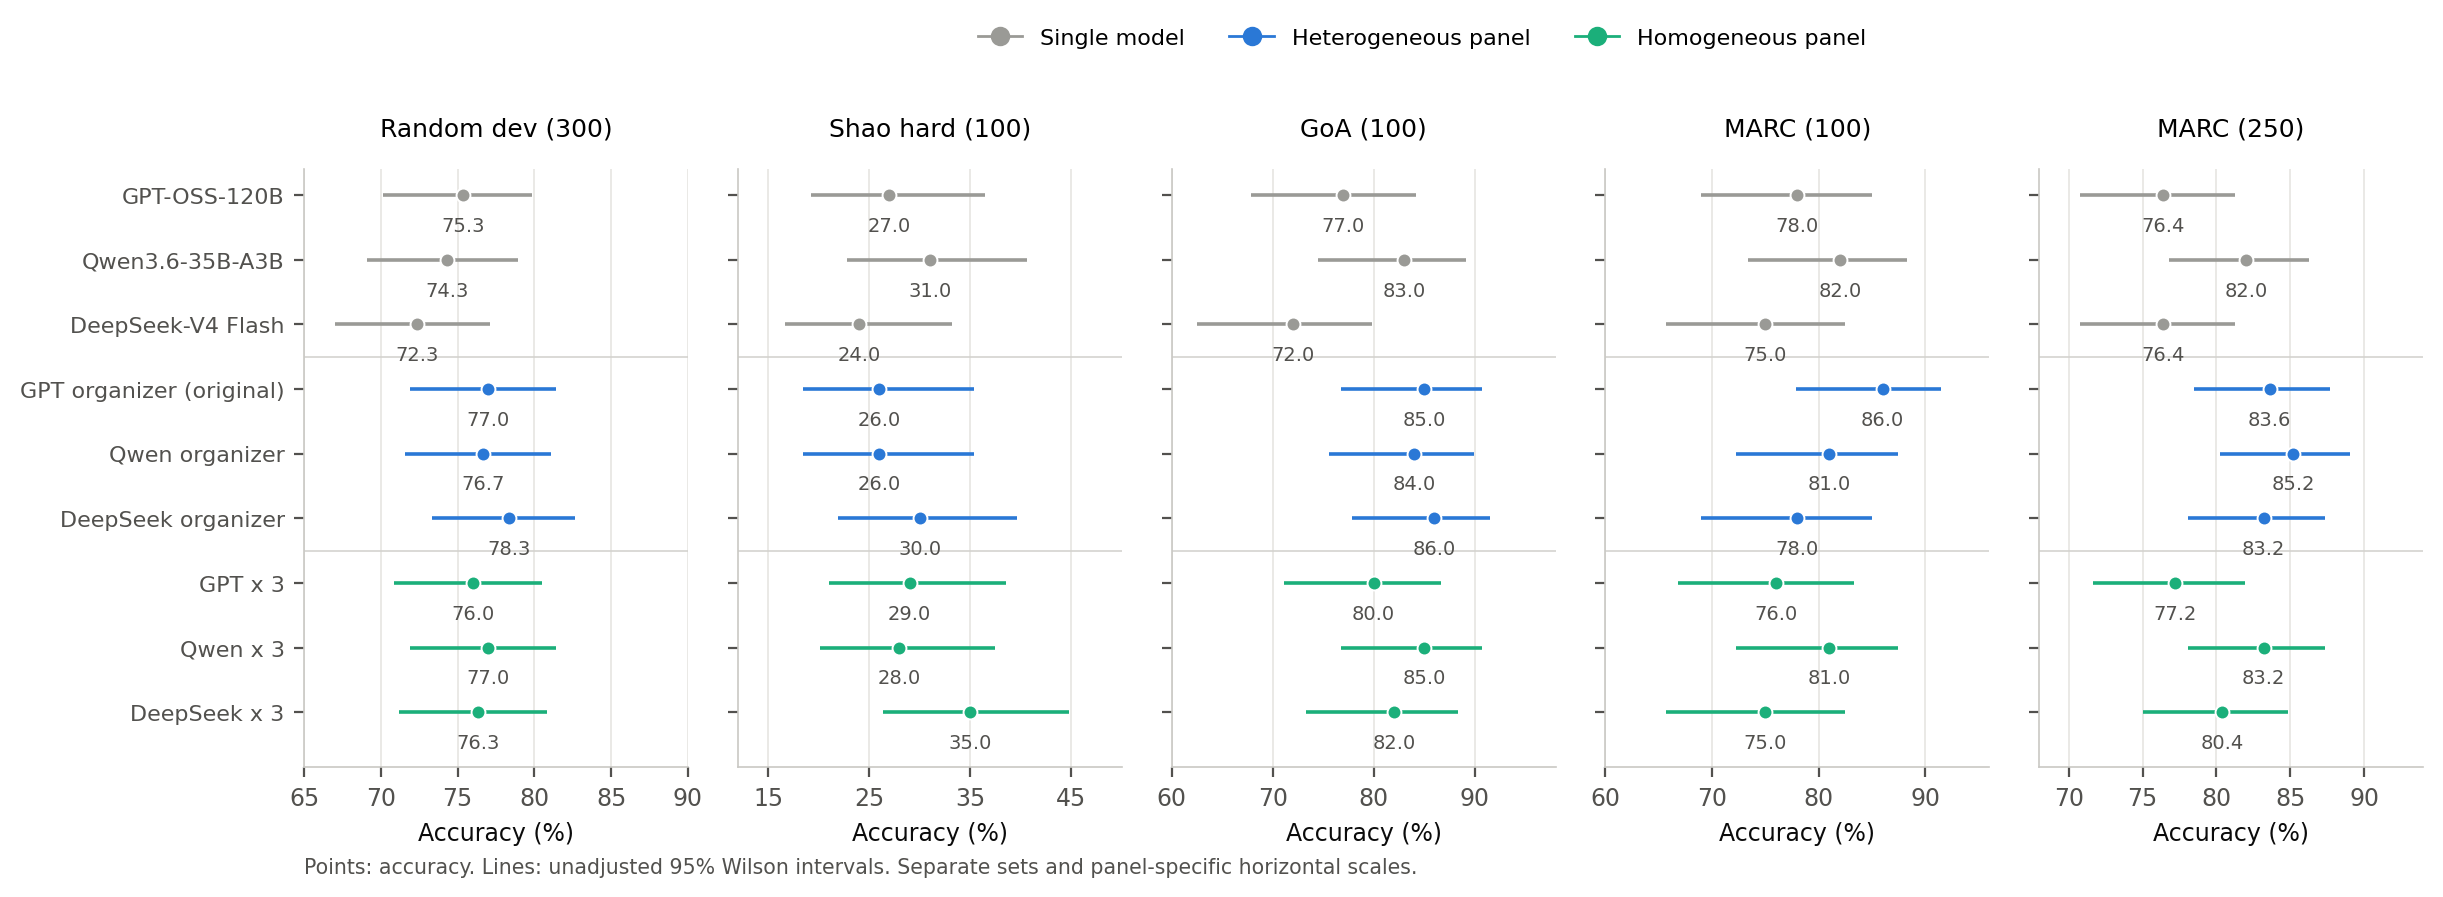

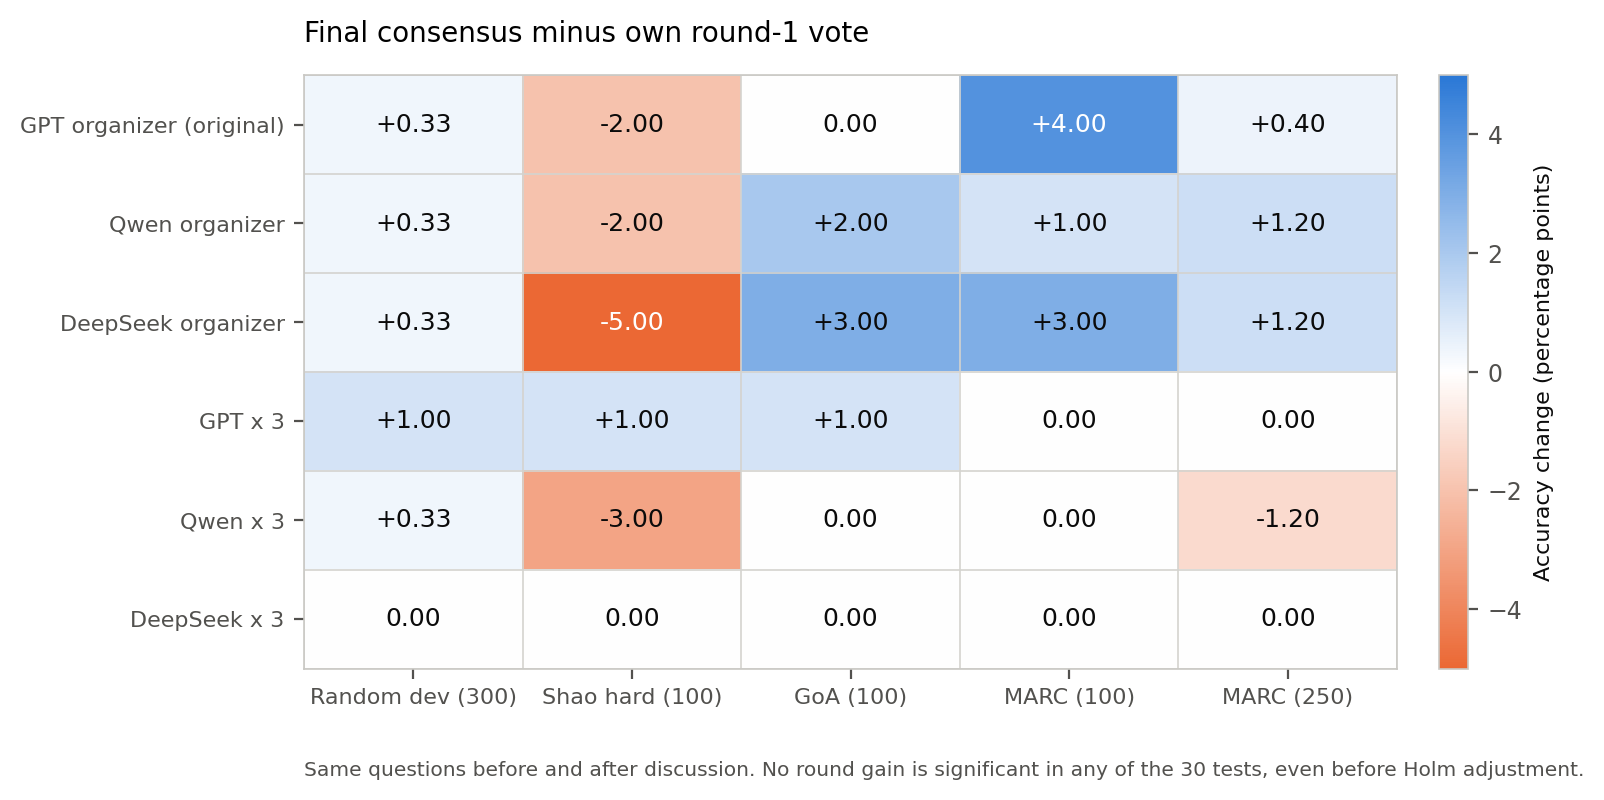

In [8]:
figure_outputs = create_figures()
display(Image(filename=str(ANALYSIS / 'medmcqa_accuracy_panels.png')))
display(Image(filename=str(ANALYSIS / 'medmcqa_round_gain.png')))
